In [1]:
import os
import sys

module_path = os.path.join(os.getcwd(), '..', 'module')
sys.path.append(module_path)

from Data_preparation import data_for_clust
from Data_preparation import quantity_executors
from Data_preparation import quantity_all
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

In [3]:
from sklearn.cluster import KMeans, MeanShift, AgglomerativeClustering

In [4]:
not_changed_df = pd.read_excel('../../data/Здания_Финальная_версия_ред.xlsx', 'Финальная ред')


In [5]:
clusters_df = pd.read_excel('../R/результаты_кластеризации.xlsx')

In [6]:
clusters_df.columns = [c.replace(".", " ") for c in clusters_df.columns]


In [7]:
clusters_df = clusters_df[["ИНН исполнителя", "Cluster"]]

In [8]:
    not_changed_df['ИНН исполнителя'] = not_changed_df['ИНН исполнителя'].apply(
            lambda x: f"{int(x):.0f}" if pd.notna(x) else ''
        )

In [9]:
not_changed_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей


In [10]:
print(quantity_all(not_changed_df))

Общее количество контрактов: 1000
Общая сумма контрактов: 2838964547.38
Общее количество исполнителей: 389
None


In [11]:
first_df = data_for_clust('../../data/Здания_Финальная_версия_ред.xlsx', 'Финальная ред')

first_df = first_df.drop(0).reset_index(drop=True)


clust_data = first_df[['ИНН исполнителя', 'Средняя цена контракта', 'Количество контрактов']]


clust_data = clust_data.copy()

clust_data['Средняя цена контракта log'] = np.log1p(clust_data['Средняя цена контракта'])
clust_data['Количество контрактов log'] = np.log1p(clust_data['Количество контрактов'])

clust_data_new = clust_data.drop(['Средняя цена контракта', 'ИНН исполнителя', 'Количество контрактов'], axis=1)

In [12]:
first_df

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков
0,1001146420,200000.00,200000.000,200000.00,199990.25,199990.250,1,3732000.0,3277000.0,455000.0,1,0,0
1,1001333318,280192.52,280192.520,280192.52,246645.01,246645.010,1,61659000.0,24491000.0,37168000.0,1,0,0
2,102002711630,786656.66,786656.660,786656.66,786656.66,786656.660,1,NaN,NaN,0.0,0,0,0
3,141701766795,204449.00,102224.500,140000.00,74767.36,37383.680,2,NaN,NaN,0.0,2,0,1
4,2100009963,554000.00,277000.000,438000.00,554000.00,277000.000,2,1756000.0,729000.0,1027000.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,7843302537,14000.00,14000.000,14000.00,14000.00,14000.000,1,NaN,NaN,0.0,0,0,0
384,7843307888,331626.57,331626.570,331626.57,331626.57,331626.570,1,NaN,NaN,0.0,0,0,0
385,8610006030,2017459.58,403491.916,475204.20,2017459.58,403491.916,5,22056000.0,14090000.0,7966000.0,0,2,0
386,8610031653,1543683.74,1543683.740,1543683.74,1543683.74,1543683.740,1,1870000.0,1117000.0,753000.0,0,0,0


In [13]:
column_names = clust_data_new.columns
index_names = clust_data_new.index

scaler = MinMaxScaler()
clust_data_scaled = scaler.fit_transform(clust_data_new)

clust_data_scaled = pd.DataFrame(clust_data_scaled, 
                                columns=column_names,
                                index=index_names)


print(clust_data_scaled.head())

   Средняя цена контракта log  Количество контрактов log
0                    0.360826                   0.000000
1                    0.393099                   0.000000
2                    0.491914                   0.000000
3                    0.296583                   0.100287
4                    0.392002                   0.100287


In [14]:
clust_data_scaled.head()

,Средняя цена контракта log,Количество контрактов log
0,0.360826,0.000000
1,0.393099,0.000000
2,0.491914,0.000000
3,0.296583,0.100287
4,0.392002,0.100287


In [15]:
clust_data_scaled.describe()

,Средняя цена контракта log,Количество контрактов log
count,388.000000,388.000000
mean,0.441862,0.069337
std,0.200048,0.136774
min,0.000000,0.000000
25%,0.306039,0.000000
50%,0.417068,0.000000
75%,0.574420,0.100287
max,1.000000,1.000000


In [16]:
clust_data_scaled

,Средняя цена контракта log,Количество контрактов log
0,0.360826,0.000000
1,0.393099,0.000000
2,0.491914,0.000000
3,0.296583,0.100287
4,0.392002,0.100287
...,...,...
383,0.106283,0.000000
384,0.409231,0.000000
385,0.428007,0.271729
386,0.556443,0.000000


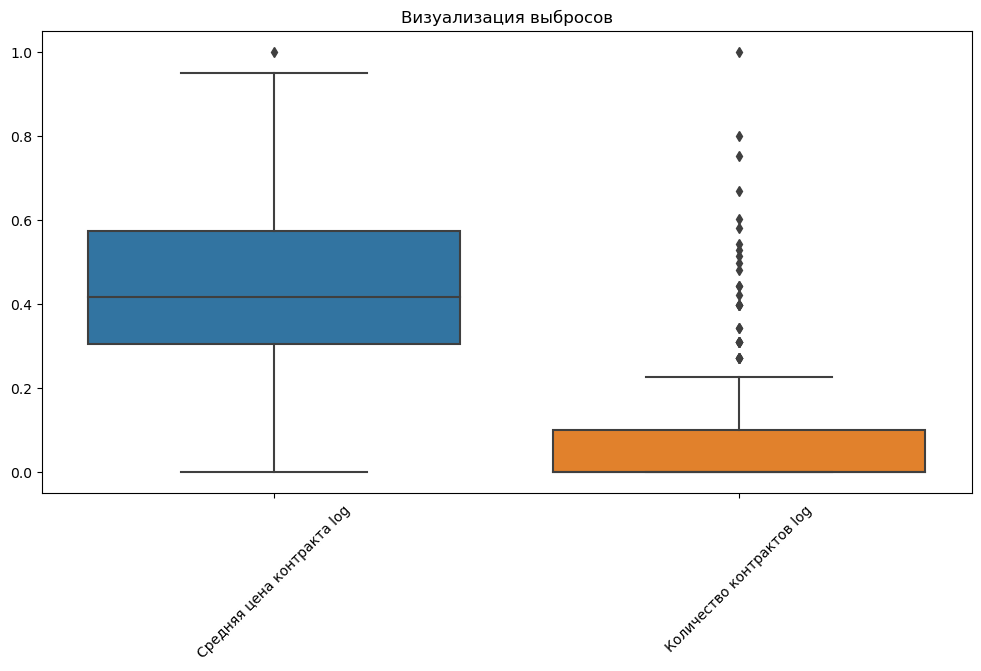

In [17]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=clust_data_scaled)
plt.xticks(rotation=45)
plt.title('Визуализация выбросов')
plt.show()

C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL

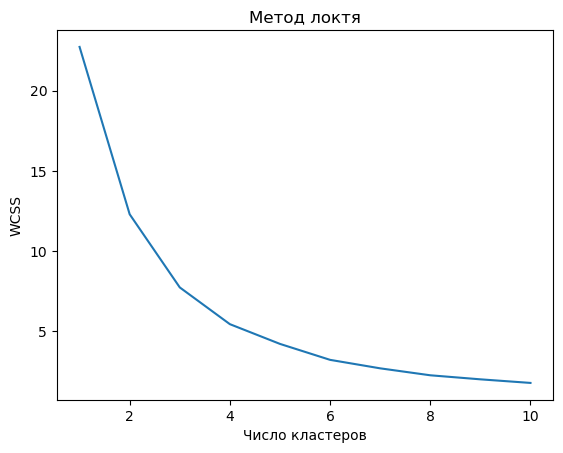

In [18]:
X = clust_data_scaled
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('Метод локтя')
plt.xlabel('Число кластеров')
plt.ylabel('WCSS')
plt.show()

In [19]:
kmeans = KMeans(n_clusters = 5, init = 'k-means++', random_state = 42)
y_kmeans = kmeans.fit_predict(X)

C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [20]:
clust_data_scaled.columns.tolist()

['Средняя цена контракта log', 'Количество контрактов log']

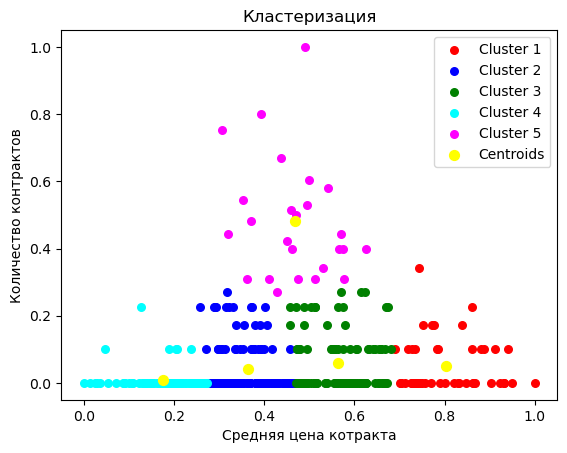

Центроиды кластеров:
   Средняя цена контракта log  Количество контрактов log  Кластер
0                    0.803768                   0.050180        0
1                    0.364621                   0.040451        1
2                    0.564043                   0.059757        2
3                    0.175711                   0.009708        3
4                    0.466966                   0.481620        4


In [22]:
clustered_data = X.copy()
clustered_data['Cluster'] = y_kmeans
clustered_data.head()

,Средняя цена контракта log,Количество контрактов log,Cluster
0,0.360826,0.000000,1
1,0.393099,0.000000,1
2,0.491914,0.000000,2
3,0.296583,0.100287,1
4,0.392002,0.100287,1


In [23]:
clustered_data = pd.concat([clust_data['ИНН исполнителя'].reset_index(drop=True), clustered_data.reset_index(drop=True)], axis=1)

In [24]:
clustered_data.head()

,ИНН исполнителя,Средняя цена контракта log,Количество контрактов log,Cluster
0,1001146420,0.360826,0.000000,1
1,1001333318,0.393099,0.000000,1
2,102002711630,0.491914,0.000000,2
3,141701766795,0.296583,0.100287,1
4,2100009963,0.392002,0.100287,1


In [25]:
data_with_clust = clust_data.copy()
data_with_clust['Cluster'] = y_kmeans
data_with_clust = data_with_clust.drop(['Средняя цена контракта log', 'Количество контрактов log'], axis = 1).round(2)
data_with_clust.head()

,ИНН исполнителя,Средняя цена контракта,Количество контрактов,Cluster
0,1001146420,200000.00,1,1
1,1001333318,280192.52,1,1
2,102002711630,786656.66,1,2
3,141701766795,102224.50,2,1
4,2100009963,277000.00,2,1


In [26]:
result = data_with_clust.groupby('Cluster').agg({
    'Средняя цена контракта': 'mean',
    'Количество контрактов': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'count'}).round(2)
result.head()

,Средняя цена контракта,Количество контрактов,count
Cluster,,,
0,30053536.71,1.60,47
1,240195.74,1.48,136
2,2075418.14,1.71,105
3,35837.09,1.11,75
4,862361.59,18.40,25


In [27]:
dbscan = DBSCAN(eps=0.09, min_samples=2)
clusters = dbscan.fit_predict(clust_data_scaled)

In [28]:
clusters

array([ 0,  0,  0,  1,  1,  0,  0,  0,  1,  1,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  1,  0,  1,  0,  0,  0,  0,  0,  0,  1,  0,
        1,  0,  0,  0,  0,  1,  1,  0,  0,  1,  0,  0,  1,  0,  0,  1,  1,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  0,  0,  0,  1,  0,  0,
        1, -1,  0,  0,  0,  0,  0,  0,  0,  1,  0,  0,  1,  0,  1,  0,  0,
        0,  0,  1,  0,  1,  1,  0,  0,  0,  0,  0,  0,  0,  1,  1,  0,  0,
        0,  1,  0,  1,  0,  0,  0,  1,  1,  1,  0,  0,  1,  1,  1,  0,  1,
        0,  0,  1,  0,  0,  1,  0,  0,  0,  1,  0,  0,  1,  0,  0,  0,  1,
        1,  1,  0,  1,  0,  0,  0,  0,  0,  1,  1,  1,  1,  0,  0,  1,  1,
        1,  0,  1,  1,  0,  1,  0,  1,  0,  0,  0,  0,  1,  1,  1,  0,  0,
        1,  1,  0,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  0,  1, -1,
        0,  1, -1,  1,  1,  1,  1, -1,  1,  1,  0,  0,  0,  1,  0,  0,  1,
        0,  0,  0, -1,  0,  1,  0,  0,  0,  1,  1,  2,  0,  0,  0,  1,  0,
        0,  1,  0,  1,  0

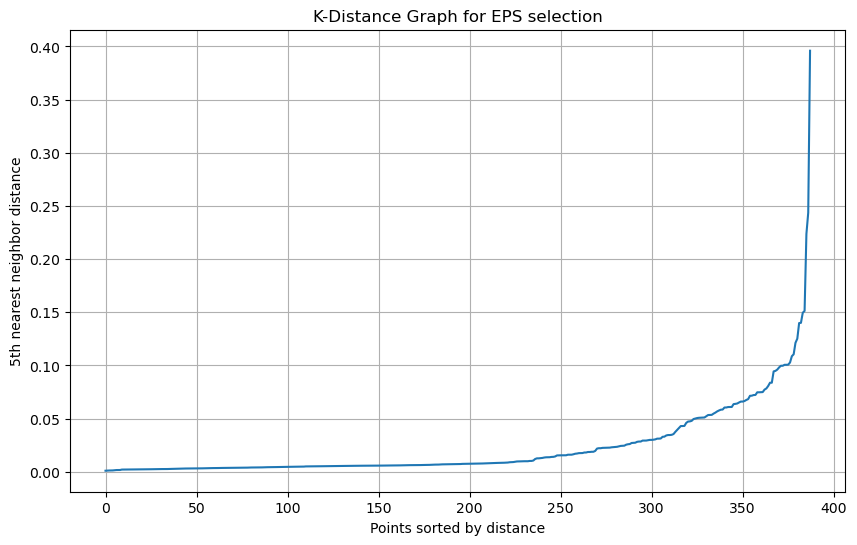

In [29]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(clust_data_scaled)
distances, indices = neighbors_fit.kneighbors(clust_data_scaled)

distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.xlabel('Points sorted by distance')
plt.ylabel('5th nearest neighbor distance')
plt.title('K-Distance Graph for EPS selection')
plt.grid(True)

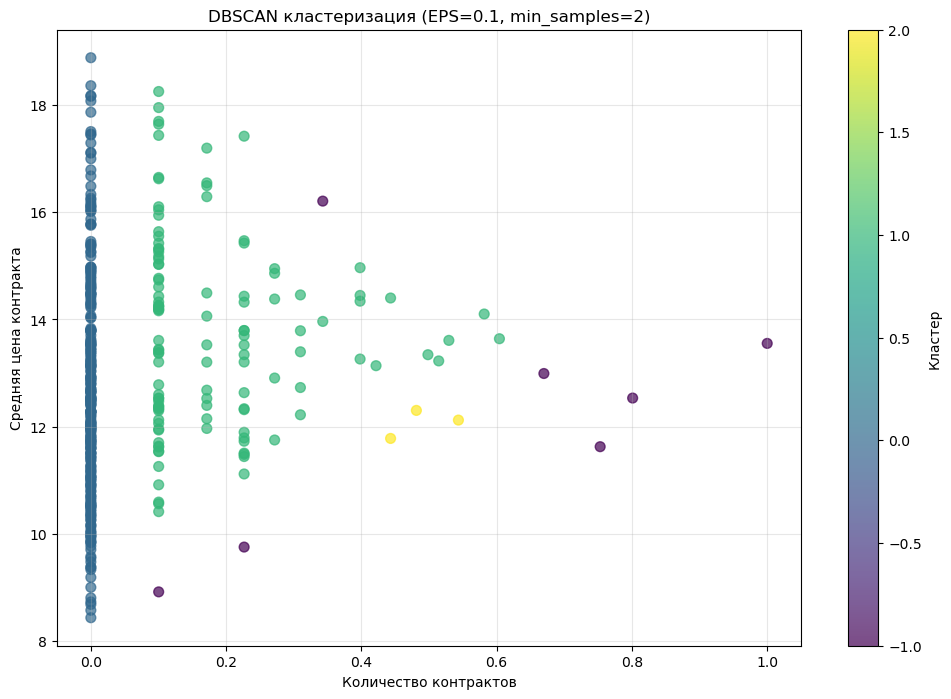

In [30]:

plt.figure(figsize=(12, 8))
scatter = plt.scatter(clust_data_scaled['Количество контрактов log'], clust_data['Средняя цена контракта log'], 
                     c=clusters, cmap='viridis', alpha=0.7, s=50)
plt.colorbar(scatter, label='Кластер')
plt.xlabel('Количество контрактов')
plt.ylabel('Средняя цена контракта')
plt.title('DBSCAN кластеризация (EPS=0.1, min_samples=2)')
plt.grid(True, alpha=0.3)

In [31]:
clust_data_scaled.head()

,Средняя цена контракта log,Количество контрактов log
0,0.360826,0.000000
1,0.393099,0.000000
2,0.491914,0.000000
3,0.296583,0.100287
4,0.392002,0.100287


In [32]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    affinity='euclidean',
    linkage='ward'
)

data = hierarchical.fit_predict(clust_data_scaled)

C:\Users\Alexander\anaconda3\Lib\site-packages\sklearn\cluster\_agglomerative.py:1005: FutureWarning: Attribute `affinity` was deprecated in version 1.2 and will be removed in 1.4. Use `metric` instead
  warnings.warn(


In [33]:
data

array([0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 0, 0, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0,
       2, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 1, 1, 0, 0, 1,
       2, 0, 1, 2, 2, 2, 1, 0, 2, 2, 2, 2, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       2, 0, 1, 1, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 2, 1, 0, 0, 0, 0, 2,
       0, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 2, 0, 2, 0, 2, 2, 2,
       1, 0, 0, 0, 1, 1, 2, 2, 2, 2, 2, 0, 2, 0, 1, 2, 0, 2, 1, 2, 0, 2,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 2, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 2, 1, 2, 1, 0, 1, 0, 0, 0, 2, 2, 1, 1, 2, 0, 1, 1, 2, 2, 0, 0,
       0, 0, 0, 2, 2, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 2, 2, 0,
       2, 0, 2, 2, 0, 1, 2, 2, 2, 1, 0, 2, 0, 0, 0, 0, 1, 1, 2, 0, 2, 1,
       0, 2, 2, 0, 0, 0, 0, 0, 2, 2, 0, 2, 1, 0, 0, 0, 0, 2, 2, 0, 1, 0,
       2, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 2, 0,
       0, 0, 0, 0, 0, 2, 2, 0, 2, 1, 1, 0, 2, 2, 0, 0, 2, 0, 2, 2, 2, 1,
       0, 0, 1, 1, 1, 0, 2, 0, 2, 0, 0, 0, 0, 0, 1,

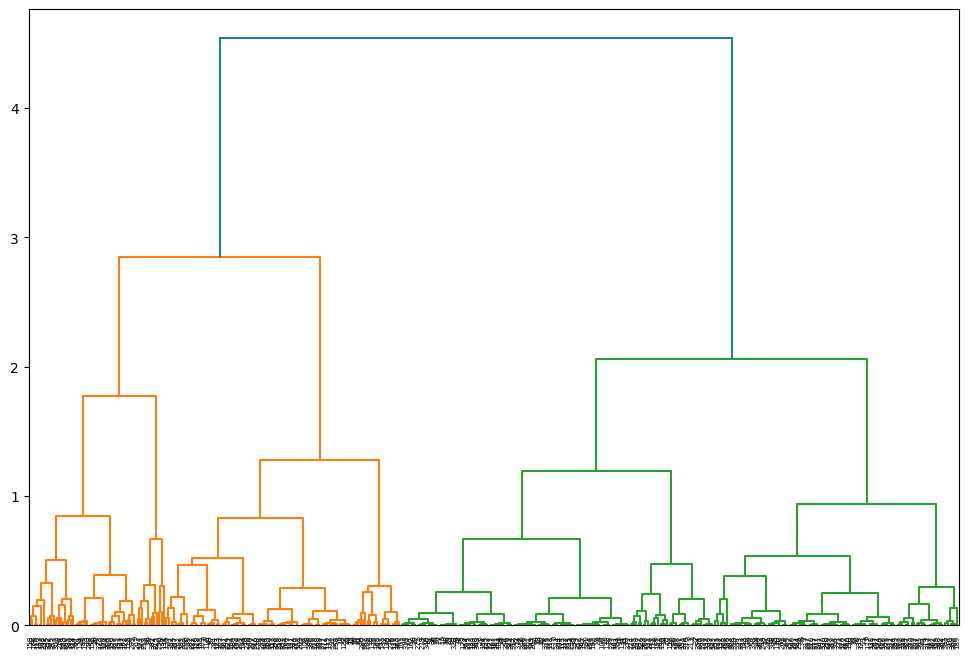

In [34]:
linked = linkage(clust_data_scaled, method='ward')

plt.figure(figsize=(12, 8))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True,
           truncate_mode='level',
           )
plt.show()

In [35]:
clust_data_scaled.head()

,Средняя цена контракта log,Количество контрактов log
0,0.360826,0.000000
1,0.393099,0.000000
2,0.491914,0.000000
3,0.296583,0.100287
4,0.392002,0.100287


In [36]:
clust_data_scaled.to_excel('Здания для кластеризации.xlsx', index=False)

In [37]:
clust_data_ex = clust_data.copy()
clust_data_ex = clust_data_ex.drop(['Средняя цена контракта log', 'Количество контрактов log'], axis = 1)
clust_data_ex.head()

,ИНН исполнителя,Средняя цена контракта,Количество контрактов
0,1001146420,200000.00,1
1,1001333318,280192.52,1
2,102002711630,786656.66,1
3,141701766795,102224.50,2
4,2100009963,277000.00,2


In [38]:
clust_data_ex.to_excel('Здания для кластеризации 2.xlsx', index=False)

In [39]:
first_df[["ИНН исполнителя", "Средняя цена контракта", "Количество контрактов", "Прибыль(убыток)"]].to_excel('Здания для кластеризации 3.xlsx', index=False)

In [40]:
first_df

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков
0,1001146420,200000.00,200000.000,200000.00,199990.25,199990.250,1,3732000.0,3277000.0,455000.0,1,0,0
1,1001333318,280192.52,280192.520,280192.52,246645.01,246645.010,1,61659000.0,24491000.0,37168000.0,1,0,0
2,102002711630,786656.66,786656.660,786656.66,786656.66,786656.660,1,NaN,NaN,0.0,0,0,0
3,141701766795,204449.00,102224.500,140000.00,74767.36,37383.680,2,NaN,NaN,0.0,2,0,1
4,2100009963,554000.00,277000.000,438000.00,554000.00,277000.000,2,1756000.0,729000.0,1027000.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,7843302537,14000.00,14000.000,14000.00,14000.00,14000.000,1,NaN,NaN,0.0,0,0,0
384,7843307888,331626.57,331626.570,331626.57,331626.57,331626.570,1,NaN,NaN,0.0,0,0,0
385,8610006030,2017459.58,403491.916,475204.20,2017459.58,403491.916,5,22056000.0,14090000.0,7966000.0,0,2,0
386,8610031653,1543683.74,1543683.740,1543683.74,1543683.74,1543683.740,1,1870000.0,1117000.0,753000.0,0,0,0


In [41]:
similarity_df = first_df.drop(["Сумма контрактов", "Сумма оплат"], axis = 1)

In [42]:
# similarity_df = similarity_df.drop(0).reset_index(drop=True)

In [43]:
similarity_df.describe()

,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков
count,3.880000e+02,3.880000e+02,3.880000e+02,388.000000,2.160000e+02,2.160000e+02,3.880000e+02,388.000000,388.000000,388.000000
mean,4.348837e+06,5.248098e+06,4.248070e+06,2.574742,3.777796e+08,3.233390e+08,3.030714e+07,0.296392,0.115979,0.033505
std,1.423191e+07,1.603343e+07,1.415344e+07,7.059151,1.525874e+09,1.193285e+09,2.992880e+08,0.916282,0.448313,0.180184
min,4.611630e+03,4.611630e+03,4.611630e+03,1.000000,0.000000e+00,2.680000e+05,-2.982300e+07,0.000000,0.000000,0.000000
25%,1.128394e+05,1.293130e+05,1.119132e+05,1.000000,2.023725e+07,1.766825e+07,0.000000e+00,0.000000,0.000000,0.000000
50%,3.599197e+05,4.684895e+05,3.318468e+05,1.000000,6.143750e+07,5.503100e+07,7.350000e+04,0.000000,0.000000,0.000000
75%,1.862629e+06,2.352865e+06,1.829647e+06,2.000000,2.058785e+08,1.944278e+08,5.085000e+06,0.000000,0.000000,0.000000
max,1.588530e+08,1.588530e+08,1.588530e+08,113.000000,1.965510e+10,1.507835e+10,4.576749e+09,12.000000,5.000000,1.000000


In [44]:
similarity_df.isna().sum().sum()

344

In [45]:
similarity = similarity_df.copy()

similarity['Рентабельность продаж'] = (( \
    similarity['Прибыль(убыток)'] / similarity['Доходы']) \
    .where(similarity['ИНН исполнителя'].astype(str).str.len() == 10)) \
    .replace([np.inf, -np.inf, np.nan], 0)

similarity['Доля прекращенных контрактов'] = (similarity['Количество прекращенных контрактов'] / similarity['Количество контрактов']) \
    .replace([np.inf, -np.inf, np.nan], 0)
    
similarity['Доля штрафных контрактов'] = (similarity['Неустойки (штрафы и пени)'] / similarity['Количество контрактов']) \
    .replace([np.inf, -np.inf, np.nan], 0)
    
similarity['Доля контракта от доходов'] = (( \
    similarity['Средняя цена контракта'] / similarity['Доходы']) \
    .where(similarity['ИНН исполнителя'].astype(str).str.len() == 10)) \
    .replace([np.inf, -np.inf, np.nan], 0)

similarity['Доля оплаты от цены контракта'] = (
    similarity['Средняя сумма оплат'] / similarity['Средняя цена контракта']
    )

fin_cols = ["Прибыль(убыток)", "Доля контракта от доходов", "Рентабельность продаж"]
similarity["Прибыль(убыток)"] = np.log1p(similarity["Прибыль(убыток)"])

scaler = MinMaxScaler()
df_fin_scaled = pd.DataFrame(scaler.fit_transform(similarity[fin_cols]), columns = fin_cols)

similarity["Финансовая устойчивость"] = df_fin_scaled.mean(axis = 1)
# similarity['Флаг цены'] = (
#     (similarity['Максимальная цена контракта'] > 250_000_000 * 0.2)
#     .astype(int)
# )

# similarity['Флаг контрактов'] = (
#     (similarity['Количество контрактов'] > 1)
#     .astype(int)
# )

# similarity['Флаг рентабельности'] = ((
#     similarity['Прибыль(убыток)'] / similarity['Доходы']
#     ).where(similarity['ИНН исполнителя'].astype(str).str.len() == 10) > 0.15).astype(int)
    

# similarity['Флаг прекращенных контрактов'] = (
#     (similarity['Количество прекращенных контрактов'] == 0)
#     .astype(int)
# )

# similarity['Флаг штрафов'] = (
#     (similarity['Неустойки (штрафы и пени)'] == 0)
#     .astype(int)
# )

# similarity['Флаг реестра'] = (
#     (similarity['Включение в реестр недобросовестных поставщиков'] == 0)
#     .astype(int)
# )

C:\Users\Alexander\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [46]:
similarity[fin_cols]

,Прибыль(убыток),Доля контракта от доходов,Рентабельность продаж
0,13.028055,0.053591,0.121919
1,17.430959,0.004544,0.602799
2,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000
4,13.842153,0.157745,0.584852
...,...,...,...
383,0.000000,0.000000,0.000000
384,0.000000,0.000000,0.000000
385,15.890693,0.018294,0.361172
386,13.531822,0.825499,0.402674


In [47]:
df_fin_scaled.describe()

,Прибыль(убыток),Доля контракта от доходов,Рентабельность продаж
count,371.000000,388.000000,388.000000
mean,0.364562,0.004220,0.608549
std,0.345280,0.050938,0.075373
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.582827
50%,0.539808,0.000008,0.584517
75%,0.695858,0.000684,0.610113
max,1.000000,1.000000,1.000000


In [48]:
similarity.describe()

,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость
count,3.880000e+02,3.880000e+02,3.880000e+02,388.000000,2.160000e+02,2.160000e+02,371.000000,388.000000,388.000000,388.000000,388.000000,388.000000,388.000000,388.000000,388.000000,388.000000
mean,4.348837e+06,5.248098e+06,4.248070e+06,2.574742,3.777796e+08,3.233390e+08,8.109409,0.296392,0.115979,0.033505,0.056600,0.124252,0.049077,0.150786,0.974557,0.324162
std,1.423191e+07,1.603343e+07,1.415344e+07,7.059151,1.525874e+09,1.193285e+09,7.680500,0.916282,0.448313,0.180184,0.165855,0.299870,0.194549,1.820205,0.102471,0.128303
min,4.611630e+03,4.611630e+03,4.611630e+03,1.000000,0.000000e+00,2.680000e+05,0.000000,0.000000,0.000000,0.000000,-1.282481,0.000000,0.000000,0.000000,0.040000,0.000671
25%,1.128394e+05,1.293130e+05,1.119132e+05,1.000000,2.023725e+07,1.766825e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.194276
50%,3.599197e+05,4.684895e+05,3.318468e+05,1.000000,6.143750e+07,5.503100e+07,12.007628,0.000000,0.000000,0.000000,0.003719,0.000000,0.000000,0.000272,1.000000,0.364334
75%,1.862629e+06,2.352865e+06,1.829647e+06,2.000000,2.058785e+08,1.944278e+08,15.478841,0.000000,0.000000,0.000000,0.060041,0.000000,0.000000,0.024437,1.000000,0.436048
max,1.588530e+08,1.588530e+08,1.588530e+08,113.000000,1.965510e+10,1.507835e+10,22.244255,12.000000,5.000000,1.000000,0.917967,1.000000,1.000000,35.733845,1.587558,0.722266


In [49]:
similarity = similarity.drop([
                             "Доходы", "Расходы", "Прибыль(убыток)",
                             "Включение в реестр недобросовестных поставщиков"], axis = 1)

In [50]:
first_df

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков
0,1001146420,200000.00,200000.000,200000.00,199990.25,199990.250,1,3732000.0,3277000.0,455000.0,1,0,0
1,1001333318,280192.52,280192.520,280192.52,246645.01,246645.010,1,61659000.0,24491000.0,37168000.0,1,0,0
2,102002711630,786656.66,786656.660,786656.66,786656.66,786656.660,1,NaN,NaN,0.0,0,0,0
3,141701766795,204449.00,102224.500,140000.00,74767.36,37383.680,2,NaN,NaN,0.0,2,0,1
4,2100009963,554000.00,277000.000,438000.00,554000.00,277000.000,2,1756000.0,729000.0,1027000.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,7843302537,14000.00,14000.000,14000.00,14000.00,14000.000,1,NaN,NaN,0.0,0,0,0
384,7843307888,331626.57,331626.570,331626.57,331626.57,331626.570,1,NaN,NaN,0.0,0,0,0
385,8610006030,2017459.58,403491.916,475204.20,2017459.58,403491.916,5,22056000.0,14090000.0,7966000.0,0,2,0
386,8610031653,1543683.74,1543683.740,1543683.74,1543683.74,1543683.740,1,1870000.0,1117000.0,753000.0,0,0,0


In [51]:
clusters_df["ИНН исполнителя"] = clusters_df["ИНН исполнителя"].astype("object")

In [52]:
clusters_df['ИНН исполнителя'] = (
    clusters_df['ИНН исполнителя']
    .astype(str)                           
    .str.strip()                            
    .str.replace(r'\.0$', '', regex=True)   
    .str.replace(r'\D', '', regex=True)    
)

In [53]:
full_df = pd.merge(not_changed_df, similarity, on="ИНН исполнителя", how="left")
full_df = pd.merge(full_df, clusters_df, on="ИНН исполнителя", how="left")

In [54]:
full_df

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,Cluster
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2782700967624000195,650803058133,НАМ ИГОРЬ САНУНОВИЧ Индивидуальный предпринима...,Исполнение завершено,3.722000e+17,2024-09-27,2024-12-31,396100.00,396100.00,NaN,NaN,Нет,нет,NaN,NaN,0.0,Деятельность консультативная в области компьют...,3.961000e+05,396100.00,3.961000e+05,1.0,0.0,0.0,0.000000,0.00000,0.00000,0.000000,1.000000,0.194276,2.0
996,1782541336124000003,7806272267,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АНГЕ...",Исполнение завершено,1.721000e+17,2024-01-26,2024-10-31,1154340.00,1154340.00,NaN,NaN,Нет,нет,249909000.0,241730000.0,8179000.0,Деятельность по общей уборке зданий,3.675016e+07,95869036.11,3.515528e+07,4.0,2.0,0.0,0.032728,0.50000,0.00000,0.147054,0.956602,0.439125,6.0
997,2781107085123000033,7838365179,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ВИНТ...",Исполнение завершено,3.722001e+17,2023-01-30,2024-08-15,57472146.00,57472146.00,NaN,NaN,Нет,нет,NaN,NaN,0.0,"Деятельность вспомогательная прочая, связанная...",5.747215e+07,57472146.00,5.747215e+07,1.0,0.0,0.0,0.000000,0.00000,0.00000,0.000000,1.000000,0.194276,6.0
998,2780610387924000025,780245145331,БУДНИК АЛЕКСАНДРА ВЛАДИМИРОВНА Индивидуальный ...,Исполнение завершено,3.722003e+17,2024-03-04,2024-12-31,65000.00,65000.00,NaN,NaN,Нет,нет,NaN,NaN,0.0,"Деятельность, связанная с инженерно-технически...",6.500000e+04,65000.00,6.500000e+04,1.0,0.0,0.0,0.000000,0.00000,0.00000,0.000000,1.000000,0.1

In [55]:
full_df = full_df.dropna(subset=["ИНН исполнителя"])
full_df = full_df[full_df["ИНН исполнителя"].str.strip() != ""]
full_df = full_df.reset_index(drop=True)

In [56]:
# full_df = full_df.dropna(subset=["Рентабельность продаж"])

In [57]:
full_df.head(50)

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,Cluster
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
5,2780514545025000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
6,2780516644225000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Да,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
7,2780514935925000013,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,108528.16,108528.16,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
8,2780514490725000020,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-10,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,4.0
9,2780514541025000019,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВ

In [58]:
full_df.sort_values(by = "Количество прекращенных контрактов").head(50)

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,Cluster
302,2781900083123000319,7810720948,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""МЕДТ...",Исполнение завершено,3.722000e+17,2023-11-20,2025-02-28,2462499.96,2462499.96,NaN,NaN,Нет,нет,3.205200e+07,2.948600e+07,2.566000e+06,Управление недвижимым имуществом за вознагражд...,1.332064e+06,2899000.00,1.332064e+06,20.0,0.0,0.0,0.080057,0.0,0.00,0.041559,1.000000,0.427939,4.0
735,2782568008524000164,7842384079,"ТОВАРИЩЕСТВО СОБСТВЕННИКОВ ЖИЛЬЯ ""КИРОЧНАЯ 32-...",Исполнение завершено,NaN,2024-12-21,2024-12-31,158185.19,158185.19,NaN,NaN,Нет,нет,NaN,NaN,0.000000e+00,Управление эксплуатацией жилого фонда за возна...,1.581852e+05,158185.19,1.581852e+05,1.0,0.0,0.0,0.000000,0.0,0.00,0.000000,1.000000,0.194276,1.0
734,2782568008524000044,7841404477,"ТОВАРИЩЕСТВО СОБСТВЕННИКОВ ЖИЛЬЯ ""ШПАЛЕРНАЯ 26...",Исполнение завершено,NaN,2024-04-16,2024-12-31,756492.72,756492.72,NaN,NaN,Нет,нет,NaN,NaN,0.000000e+00,Управление недвижимым имуществом за вознагражд...,7.564927e+05,756492.72,7.564927e+05,1.0,0.0,0.0,0.000000,0.0,0.00,0.000000,1.000000,0.194276,2.0
733,2780733575224000015,7807335047,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ЖИЛК...",Исполнение завершено,NaN,2024-01-29,2024-12-31,101658.30,101658.30,NaN,NaN,Нет,нет,3.323120e+08,3.235010e+08,8.811000e+06,Управление эксплуатацией жилого фонда за возна...,1.270192e+05,228933.00,1.270192e+05,5.0,0.0,0.0,0.026514,0.0,0.00,0.000382,1.000000,0.437931,3.0
732,2780733575224000134,7807335047,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ЖИЛК...",Исполнение завершено,NaN,2024-08-28,2024-12-31,228933.00,228933.00,NaN,NaN,Нет,нет,3.323120e+08,3.235010e+08,8.811000e+06,Управление эксплуатацией жилого фонда за возна...,1.270192e+05,228933.00,1.270192e+05,5.0,0.0,0.0,0.026514,0.0,0.00,0.000382,1.000000,0.437931,3.0
731,2781703236224000001,7811564716,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ДОРО...",Исполнение завершено,3.722002e+17,2023-12-29,2024-12-31,1737750.00,1737750.00,NaN,NaN,Нет,нет,3.881200e+07,4.100500e+07,-2.193000e+06,Деятельность автомобильного грузового транспорта,3.358875e+06,4980000.00,3.358875e+06,2.0,0.0,0.0,-0.056503,0.0,0.00,0.086542,1.000000,0.279785,2.0
398,2782001667424000005,7804605200,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""РЕМО...",Исполнение завершено,3.722002e+17,2023-12-31,2025-01-31,4585900.00,4585900.00,NaN,NaN,Нет,нет,7.098000e+06,5.701000e+06,1.397000e+06,Разборка и снос зданий,2.592121e+06,4585900.00,2.592121e+06,2.0,0.0,0.0,0.196816,0.0,0.00,0.365190,1.000000,0.439534,2.0
736,2782568008524000179,7842338386,"ТОВАРИЩЕСТВО СОБСТВЕННИКОВ ЖИЛЬЯ ""НОВАТОР"" (ТС...",Исполнение завершено,NaN,2024-12-23,2024-12-31,22406.10,22406.10,NaN,NaN,Нет,нет,NaN,NaN,0.000000e+00,Управление эксплуатацией жилого фонда за возна...,2.240610e+04,22406.10,2.240610e+04,1.0,0.0,0.0,0.000000,0.0,0.00,0.000000,1.000000,0.194276,5.0
730,2780804654523000154,7813419263,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ЖИЛК...",Исполнение завершено,NaN,2023-12-25,2024-12-31,61879.74,61879.74,NaN,NaN,Нет,нет,5.484910e+08,5.432720e+08,5.219000e+06,Управление недвижимым имуществом за вознагражд...,2.760366e+05,490193.54,2.760366e+05,2.0,0.0,0.0,0.009515,0.0,0.00,0.000503,1.000000,0.427509,3.0
401,2781410115222000011,2462211810,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""РЕНТ...",Исполнение завершено,1.722000e+17,2022-05-20,2024-11

In [59]:
full_df["ОКВЭД"].unique()

array(['Обеспечение работоспособности тепловых сетей',
       'Торговля оптовая прочими бытовыми товарами',
       'Деятельность по чистке и уборке жилых зданий и нежилых помещений прочая',
       'Разборка и снос зданий', 'Торговля оптовая неспециализированная',
       'Строительство жилых и нежилых зданий',
       'Предоставление прочих персональных услуг, не включенных в другие группировки',
       'Управление недвижимым имуществом за вознаграждение или на договорной основе',
       'Работы строительные специализированные прочие, не включенные в другие группировки',
       'Деятельность по общей уборке зданий',
       'Деятельность систем обеспечения безопасности',
       'Управление эксплуатацией жилого фонда за вознаграждение или на договорной основе',
       'Деятельность по обеспечению пожарной безопасности',
       'Производство электромонтажных работ',
       'Управление эксплуатацией нежилого фонда за вознаграждение или на договорной основе',
       'Разработка строительных п

In [60]:
full_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 30 columns):
 #   Column                                           Non-Null Count  Dtype         
---  ------                                           --------------  -----         
 0   Реестровый номер контракта                       999 non-null    int64         
 1   ИНН исполнителя                                  999 non-null    object        
 2   Наименование исполнителя                         999 non-null    object        
 3   Статус контракта                                 999 non-null    object        
 4   Номер извещения                                  742 non-null    float64       
 5   Дата заключения контракта                        982 non-null    datetime64[ns]
 6   Дата окончания исполнения контракта              999 non-null    datetime64[ns]
 7   Цена контракта                                   999 non-null    float64       
 8   Фактически оплачено                     

In [61]:
mean_price = full_df.groupby("Статус контракта", as_index = False).agg({'Средняя цена контракта':'mean'})

median_prices = full_df.groupby("Статус контракта", as_index = False)["Средняя цена контракта"].median()


In [62]:
mean_price

,Статус контракта,Средняя цена контракта
0,Исполнение завершено,2.685994e+06
1,Исполнение прекращено,3.925879e+06


In [63]:
median_prices

,Статус контракта,Средняя цена контракта
0,Исполнение завершено,555401.744000
1,Исполнение прекращено,769924.886991


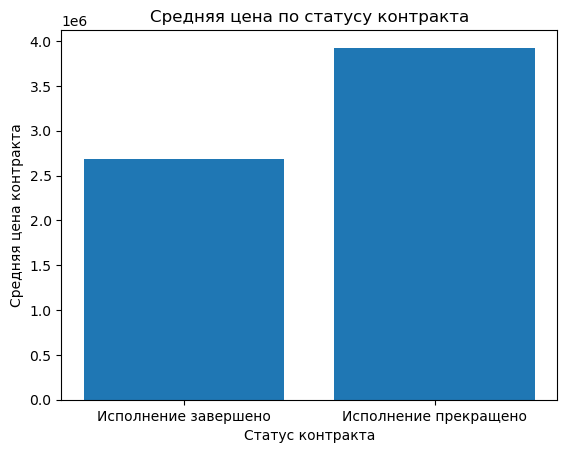

In [64]:
plt.bar(mean_price["Статус контракта"], mean_price["Средняя цена контракта"])
plt.xlabel("Статус контракта")
plt.ylabel("Средняя цена контракта")
plt.title("Средняя цена по статусу контракта")
plt.show()


In [65]:
full_df["Статус контракта"] = (full_df["Статус контракта"] == "Исполнение завершено").astype(int)

full_df["Включение в реестр недобросовестных поставщиков"] = (full_df["Включение в реестр недобросовестных поставщиков"] == "да").astype(int)

In [66]:
okved_1 = full_df.groupby("ОКВЭД", as_index=False).agg({'Доля прекращенных контрактов':'mean', 'Реестровый номер контракта':'nunique'})

In [67]:
# pd.set_option("display.max_rows", None)
okved_1

,ОКВЭД,Доля прекращенных контрактов,Реестровый номер контракта
0,Аренда и управление собственным или арендованн...,0.200000,10
1,Аренда и управление собственным или арендованн...,0.000000,1
2,"Дезинфекция, дезинсекция, дератизация зданий, ...",0.000000,1
3,Деятельность автомобильного грузового транспорта,0.000000,2
4,Деятельность агентов по оптовой торговле строи...,0.000000,1
...,...,...,...
76,Торговля электроэнергией,0.000000,1
77,Управление недвижимым имуществом за вознагражд...,0.056995,193
78,Управление эксплуатацией жилого фонда за возна...,0.096000,125
79,Управление эксплуатацией нежилого фонда за воз...,0.032787,61


In [68]:
okved_group_2 = [
    "Деятельность систем обеспечения безопасности",
    "Деятельность по обеспечению пожарной безопасности",
    "Деятельность охранных служб, в том числе частных",
    "Деятельность в области связи на базе проводных технологий",
    "Деятельность в области защиты информации прочая",
    "Деятельность по обработке данных, предоставление услуг по размещению информации и связанная с этим деятельность",
    "Деятельность консультативная в области компьютерных технологий прочая"
]

okved_1[okved_1["ОКВЭД"].isin(okved_group_2)]

,ОКВЭД,Доля прекращенных контрактов,Реестровый номер контракта
11,Деятельность в области защиты информации прочая,0.00,1
12,Деятельность в области связи на базе проводных...,0.00,3
15,Деятельность консультативная в области компьют...,0.00,1
17,"Деятельность охранных служб, в том числе частных",0.00,1
20,Деятельность по обеспечению пожарной безопасности,0.00,2
21,"Деятельность по обработке данных, предоставлен...",0.00,1
32,Деятельность систем обеспечения безопасности,0.75,16


In [69]:
okved_map = {
    # G0: Строительство и монтаж
    0: [
        "Строительство жилых и нежилых зданий",
        "Строительство водных сооружений",
        "Строительство автомобильных дорог и автомагистралей",
        "Подготовка строительной площадки",
        "Производство земляных работ",
        "Разработка строительных проектов",
        "Работы строительные специализированные прочие, не включенные в другие группировки",
        "Производство электромонтажных работ",
        "Производство санитарно-технических работ, монтаж отопительных систем и систем кондиционирования воздуха",
        "Производство прочих строительно-монтажных работ",
        "Производство штукатурных работ",
        "Производство электромонтажных, санитарно-технических и прочих строительно-монтажных работ",
        "Работы строительные отделочные",
        "Деятельность в области архитектуры",
        "Деятельность, связанная с инженерно-техническим проектированием, управлением проектами строительства, выполнением строительного контроля и авторского надзора",
        "Разборка и снос зданий"
    ],

    # G1: Эксплуатация, клининг, услуги для населения
    1: [
        "Обеспечение работоспособности тепловых сетей",
        "Деятельность по общей уборке зданий",
        "Деятельность по чистке и уборке жилых зданий и нежилых помещений прочая",
        "Деятельность по уборке прочих типов зданий и помещений",
        "Деятельность по чистке и уборке прочая",
        "Деятельность по чистке и уборке прочая, не включенная в другие группировки",
        "Деятельность по комплексному обслуживанию помещений",
        "Деятельность административно-хозяйственная комплексная по обеспечению работы организации",
        "Подметание улиц и уборка снега",
        "Деятельность по благоустройству ландшафта",
        "Дезинфекция, дезинсекция, дератизация зданий, промышленного оборудования",
        "Стирка и химическая чистка текстильных и меховых изделий",
        "Предоставление прочих персональных услуг, не включенных в другие группировки",
        "Деятельность по предоставлению прочих вспомогательных услуг для бизнеса, не включенная в другие группировки",
        "Деятельность по предоставлению прочих персональных услуг",
        "Управление недвижимым имуществом за вознаграждение или на договорной основе",
        "Управление эксплуатацией жилого фонда за вознаграждение или на договорной основе",
        "Управление эксплуатацией нежилого фонда за вознаграждение или на договорной основе",
        "Аренда и управление собственным или арендованным недвижимым имуществом",
        "Аренда и управление собственным или арендованным нежилым недвижимым имуществом",
        "Деятельность агентств недвижимости за вознаграждение или на договорной основе",
        "Покупка и продажа собственного недвижимого имущества",
        "Деятельность больничных организаций",
        "Цветоводство",
        "Деятельность рыночных киосков и торговых палаток по приготовлению пищи"
    ],

    # G2: Безопасность и ИКТ
    2: [
        "Деятельность систем обеспечения безопасности",
        "Деятельность по обеспечению пожарной безопасности",
        "Деятельность охранных служб, в том числе частных",
        "Деятельность в области связи на базе проводных технологий",
        "Деятельность в области защиты информации прочая",
        "Деятельность по обработке данных, предоставление услуг по размещению информации и связанная с этим деятельность",
        "Деятельность консультативная в области компьютерных технологий прочая"
    ],

    # G3: Торговля и логистика
    3: [
        "Торговля оптовая прочими бытовыми товарами",
        "Торговля оптовая неспециализированная",
        "Торговля оптовая лесоматериалами, строительными материалами и санитарно-техническим оборудованием",
        "Торговля оптовая прочими строительными материалами и изделиями",
        "Торговля оптовая бытовыми электротоварами",
        "Торговля оптовая электрической бытовой техникой",
        "Торговля розничная бытовыми электротоварами в специализированных магазинах",
        "Торговля розничная по почте или по информационно-коммуникационной сети Интернет",
        "Торговля розничная, осуществляемая непосредственно при помощи информационно-коммуникационной сети Интернет",
        "Торговля розничная мужской, женской и детской одеждой в специализированных магазинах",
        "Деятельность агентов по оптовой торговле строительными материалами",
        "Деятельность агентов по оптовой торговле универсальным ассортиментом товаров",
        "Деятельность автомобильного грузового транспорта",
        "Деятельность вспомогательная прочая, связанная с перевозками",
        "Деятельность аэропортовая",
        "Деятельность вспомогательная, связанная с воздушным и космическим транспортом"
    ],

    # G4: Профессиональные и экологические услуги
    4: [
        "Обработка и утилизация опасных отходов",
        "Сбор и обработка сточных вод",
        "Производство электроэнергии",
        "Передача электроэнергии и технологическое присоединение к распределительным электросетям",
        "Торговля электроэнергией",
        "Производство, передача и распределение пара и горячей воды; кондиционирование воздуха",
        "Деятельность организаций санитарно-эпидемиологической службы",
        "Консультирование по вопросам коммерческой деятельности и управления",
        "Научные исследования и разработки в области естественных и технических наук прочие",
        "Деятельность профессиональная, научная и техническая прочая, не включенная в другие группировки",
        "Деятельность по управлению холдинг-компаниями",
        "Сертификация продукции, услуг и организаций"
    ]
}

okved_to_class = {okved: group for group, okveds in okved_map.items() for okved in okveds}

full_df["ОКВЭД_класс"] = full_df["ОКВЭД"].map(okved_to_class).fillna(5)

In [70]:
full_df

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,Cluster,ОКВЭД_класс
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,2782700967624000195,650803058133,НАМ ИГОРЬ САНУНОВИЧ Индивидуальный предпринима...,1,3.722000e+17,2024-09-27,2024-12-31,396100.00,396100.00,NaN,NaN,Нет,0,NaN,NaN,0.0,Деятельность консультативная в области компьют...,3.961000e+05,396100.00,3.961000e+05,1.0,0.0,0.0,0.000000,0.00000,0.00000,0.000000,1.000000,0.194276,2.0,2.0
995,1782541336124000003,7806272267,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АНГЕ...",1,1.721000e+17,2024-01-26,2024-10-31,1154340.00,1154340.00,NaN,NaN,Нет,0,249909000.0,241730000.0,8179000.0,Деятельность по общей уборке зданий,3.675016e+07,95869036.11,3.515528e+07,4.0,2.0,0.0,0.032728,0.50000,0.00000,0.147054,0.956602,0.439125,6.0,1.0
996,2781107085123000033,7838365179,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ВИНТ...",1,3.722001e+17,2023-01-30,2024-08-15,57472146.00,57472146.00,NaN,NaN,Нет,0,NaN,NaN,0.0,"Деятельность вспомогательная прочая, связанная...",5.747215e+07,57472146.00,5.747215e+07,1.0,0.0,0.0,0.000000,0.00000,0.00000,0.000000,1.000000,0.194276,6.0,3.0
997,2780610387924000025,780245145331,БУДНИК АЛЕКСАНДРА ВЛАДИМИРОВНА Индивидуальный ...,1,3.722003e+17,2024-03-04,2024-12-31,65000.00,65000.00,NaN,NaN,Нет,0,NaN,NaN,0.0,"Деятельность, связанная с инженерно-технически...",6.500000e+04,65000.00,6.500000e+04,1.0,0.0,0.0,0.000000,0.00000,0.00000,0.000000,1.000000,0.194276,1.0,0.0


In [71]:
okved = full_df.groupby("ОКВЭД_класс", as_index=False).agg({'Доля прекращенных контрактов':'mean'})

In [72]:
okved.head()

,ОКВЭД_класс,Доля прекращенных контрактов
0,0.0,0.121406
1,1.0,0.094991
2,2.0,0.480000
3,3.0,0.090909
4,4.0,0.157895


In [73]:
full_df["ЛогЦена"] = np.log1p(full_df["Цена контракта"].clip(lower=0))
full_df["ЛогПрибыль"] = np.log1p(full_df["Прибыль(убыток)"].clip(lower=0))
# full_df["Доля оплаты"] = full_df["Фактически оплачено"]/full_df["Цена контракта"]

scaler = MinMaxScaler()

cols_to_scale = ["ЛогЦена", "ЛогПрибыль"]

full_df[cols_to_scale] = scaler.fit_transform(full_df[cols_to_scale])


In [74]:
full_df.describe()

,Реестровый номер контракта,Статус контракта,Номер извещения,Цена контракта,Фактически оплачено,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,Cluster,ОКВЭД_класс,ЛогЦена,ЛогПрибыль
count,9.990000e+02,999.000000,7.420000e+02,9.990000e+02,9.830000e+02,999.000000,7.250000e+02,7.250000e+02,9.990000e+02,9.990000e+02,9.990000e+02,9.990000e+02,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,2.659528e+18,0.884885,3.493351e+17,2.828724e+06,2.783641e+06,0.079079,3.106474e+08,2.699410e+08,2.954165e+07,2.828724e+06,4.718918e+06,2.775953e+06,21.878879,1.386386,0.801802,0.081016,0.115115,0.045045,0.109769,0.986543,0.367964,3.503504,0.954955,0.495187,0.474559
std,3.371939e+17,0.319321,1.522037e+17,1.084645e+07,1.082157e+07,0.269997,1.536942e+09,1.198246e+09,3.123342e+08,1.021052e+07,1.289413e+07,1.013732e+07,35.113020,2.313343,1.589910,0.157645,0.245691,0.145491,1.601595,0.104763,0.116642,1.262904,1.058875,0.152469,0.316276
min,1.502705e+18,0.000000,1.451000e+17,1.207380e+03,1.207380e+03,0.000000,0.000000e+00,2.680000e+05,-2.982300e+07,4.611630e+03,4.611630e+03,4.611630e+03,1.000000,0.000000,0.000000,-1.282481,0.000000,0.000000,0.000000,0.040000,0.000671,1.000000,0.000000,0.000000,0.000000
25%,2.780213e+18,1.000000,2.155750e+17,1.193389e+05,1.143873e+05,0.000000,2.900300e+07,2.668500e+07,0.000000e+00,1.867897e+05,3.297519e+05,1.844714e+05,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.990767,0.194276,3.000000,0.000000,0.389659,0.000000
50%,2.780644e+18,1.000000,3.722001e+17,3.899418e+05,3.740008e+05,0.000000,5.138800e+07,4.841100e+07,2.318000e+06,5.751067e+05,1.856058e+06,5.554017e+05,4.000000,0.000000,0.000000,0.022269,0.000000,0.000000,0.004768,1.000000,0.424438,4.000000,1.000000,0.490115,0.658876
75%,2.781703e+18,1.000000,3.722002e+17,1.184133e+06,1.078950e+06,0.000000,1.259190e+08,1.142080e+08,6.627000e+06,1.311432e+06,3.501801e+06,1.201223e+06,22.000000,1.000000,1.000000,0.080057,0.076923,0.034483,0.014983,1.000000,0.445510,4.000000,1.000000,0.584356,0.706100
max,3.781703e+18,1.000000,8.725000e+17,1.588530e+08,1.588530e+08,1.000000,1.965510e+10,1.507835e+10,4.576749e+09,1.588530e+08,1.588530e+08,1.588530e+08,113.000000,12.000000,5.000000,0.917967,1.000000,1.000000,35.733845,1.587558,0.722266,6.000000,5.000000,1.000000,1.000000


In [75]:
full_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,Cluster,ОКВЭД_класс,ЛогЦена,ЛогПрибыль
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0,0.353707,0.555012
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0,0.364075,0.555012
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0,0.475891,0.555012
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0,0.389659,0.555012
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,4.0,1.0,0.412027,0.555012


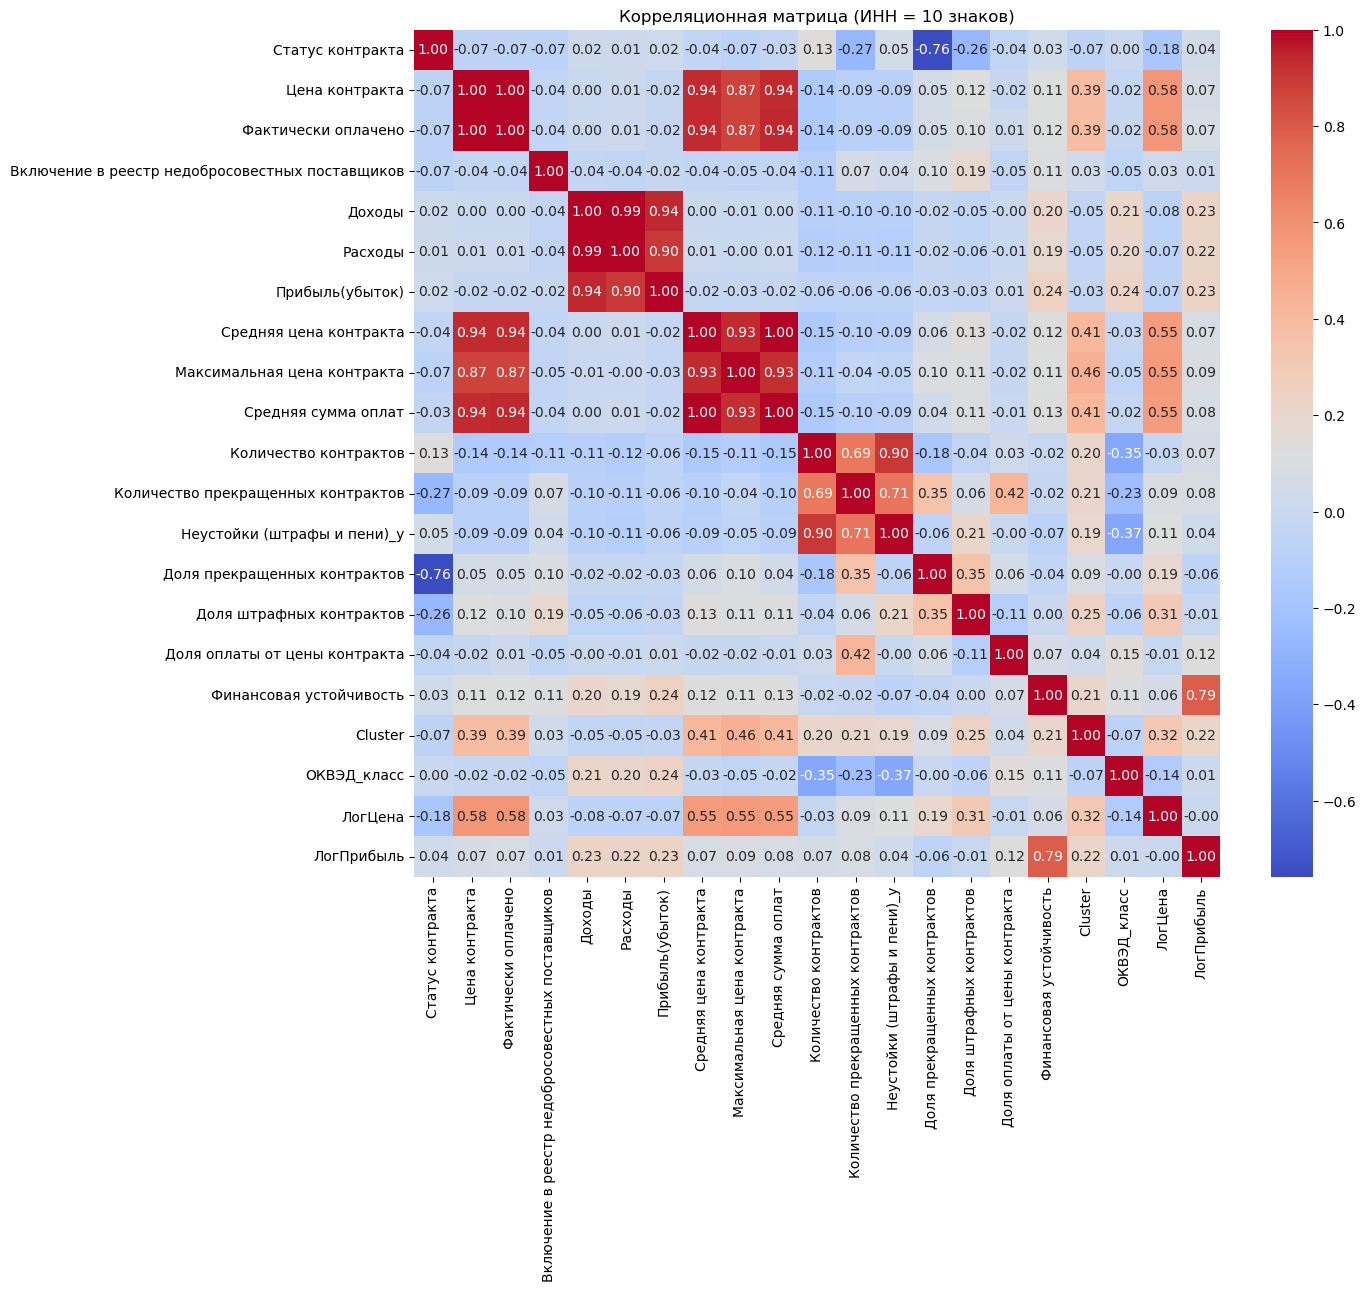

In [76]:
filtered_df = full_df[
    (full_df["ИНН исполнителя"].astype(str).str.len() == 10) &
    (full_df["Доходы"].notna()) &
    (full_df["Расходы"].notna())
]


numeric_df = filtered_df.select_dtypes(include=["number"])

numeric_df = numeric_df.drop(["Реестровый номер контракта", "Номер извещения", "Рентабельность продаж", "Доля контракта от доходов"], axis=1)

num_cols = numeric_df.columns

scaler = MinMaxScaler()

numeric_df[num_cols] = scaler.fit_transform(numeric_df[num_cols])




corr_matrix = numeric_df.corr()

plt.figure(figsize=(13,11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Корреляционная матрица (ИНН = 10 знаков)")
plt.show()


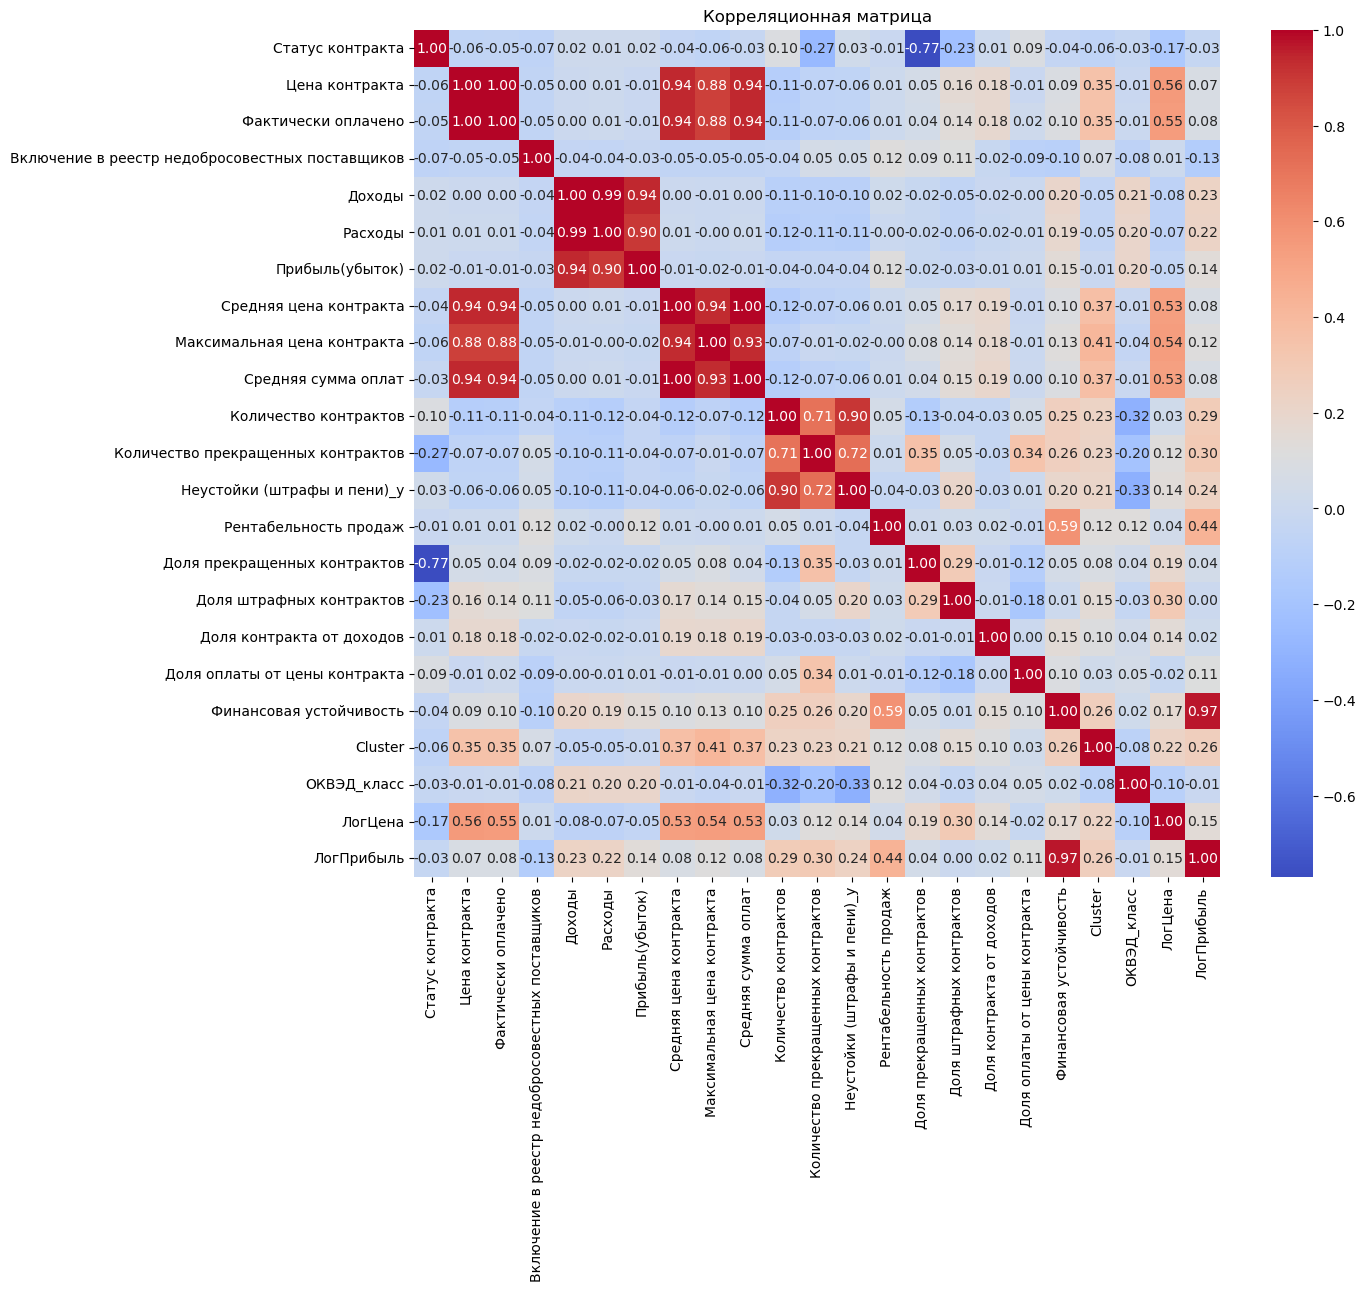

In [77]:
numeric_df = full_df.select_dtypes(include=["number"])
numeric_df = numeric_df.drop(["Реестровый номер контракта", "Номер извещения"], axis = 1)

corr_matrix = numeric_df.corr()

plt.figure(figsize=(13,11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Корреляционная матрица")
plt.show()

In [78]:
full_df = pd.get_dummies(full_df, columns = ["ОКВЭД_класс"], drop_first = True)

full_df = pd.get_dummies(full_df, columns = ["Cluster"], drop_first = True)

In [79]:
full_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0,0,1,0,0
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.364075,0.555012,1,0,0,0,0,0,0,1,0,0
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.475891,0.555012,1,0,0,0,0,0,0,1,0,0
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0,0,1,0,0
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.412027,0.555012,1,0,0,0,0,0,0,1,0,0


In [80]:
for_mean_penalties_df = full_df.copy()

for_mean_penalties_df["Средний процент недоплаты"] = 1 -(for_mean_penalties_df["Фактически оплачено"] / for_mean_penalties_df["Цена контракта"]) 

In [81]:
for_mean_penalties_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0,Средний процент недоплаты
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0,0,1,0,0,0.0
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.364075,0.555012,1,0,0,0,0,0,0,1,0,0,0.0
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.475891,0.555012,1,0,0,0,0,0,0,1,0,0,0.0
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0,0,1,0,0,0.0
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.412027,0.555012,1,0,0,0,0,0,0,1,0,0,0.0


In [82]:
mean_penalties_df = for_mean_penalties_df.groupby('ИНН исполнителя', as_index=False).agg({'Средний процент недоплаты':'mean'})

In [83]:
mean_penalties_df.head(10)

,ИНН исполнителя,Средний процент недоплаты
0,1001146420,0.000049
1,1001333318,0.119730
2,102002711630,0.000000
3,141701766795,0.620547
4,2100009963,0.000000
5,211301376106,0.000000
6,2312224779,0.000000
7,233012683520,0.000000
8,235200270142,0.028303
9,2462211810,0.159694


In [84]:
full_df = pd.merge(full_df, mean_penalties_df, on="ИНН исполнителя", how="left")

In [85]:
full_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0,Средний процент недоплаты
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0,0,1,0,0,0.000208
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.364075,0.555012,1,0,0,0,0,0,0,1,0,0,0.000208
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.475891,0.555012,1,0,0,0,0,0,0,1,0,0,0.000208
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0,0,1,0,0,0.000208
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,112101.370244,329751.93,112081.816341,41.0,1.0,1.0,0.007423,0.02439,0.02439,0.003618,0.999826,0.380438,0.412027,0.555012,1,0,0,0,0,0,0,1,0,0,0.000208


In [86]:
#---------------------
#
#Модели
#
#---------------------

In [87]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [88]:
full_df.columns

Index(['Реестровый номер контракта', 'ИНН исполнителя',
       'Наименование исполнителя', 'Статус контракта', 'Номер извещения',
       'Дата заключения контракта', 'Дата окончания исполнения контракта',
       'Цена контракта', 'Фактически оплачено',
       'Основание расторжения контракта', 'Причина расторжения контракта',
       'Неустойки (штрафы и пени)_x',
       'Включение в реестр недобросовестных поставщиков', 'Доходы', 'Расходы',
       'Прибыль(убыток)', 'ОКВЭД', 'Средняя цена контракта',
       'Максимальная цена контракта', 'Средняя сумма оплат',
       'Количество контрактов', 'Количество прекращенных контрактов',
       'Неустойки (штрафы и пени)_y', 'Рентабельность продаж',
       'Доля прекращенных контрактов', 'Доля штрафных контрактов',
       'Доля контракта от доходов', 'Доля оплаты от цены контракта',
       'Финансовая устойчивость', 'ЛогЦена', 'ЛогПрибыль', 'ОКВЭД_класс_1.0',
       'ОКВЭД_класс_2.0', 'ОКВЭД_класс_3.0', 'ОКВЭД_класс_4.0',
       'ОКВЭД_класс_5.

In [89]:
full_df.describe()

,Реестровый номер контракта,Статус контракта,Номер извещения,Цена контракта,Фактически оплачено,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0,Средний процент недоплаты
count,9.990000e+02,999.000000,7.420000e+02,9.990000e+02,9.830000e+02,999.000000,7.250000e+02,7.250000e+02,9.990000e+02,9.990000e+02,9.990000e+02,9.990000e+02,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,2.659528e+18,0.884885,3.493351e+17,2.828724e+06,2.783641e+06,0.079079,3.106474e+08,2.699410e+08,2.954165e+07,2.828724e+06,4.718918e+06,2.775953e+06,21.878879,1.386386,0.801802,0.081016,0.115115,0.045045,0.109769,0.986543,0.367964,0.495187,0.474559,0.579580,0.025025,0.033033,0.019019,0.030030,0.141141,0.114114,0.534535,0.050050,0.066066,0.024466
std,3.371939e+17,0.319321,1.522037e+17,1.084645e+07,1.082157e+07,0.269997,1.536942e+09,1.198246e+09,3.123342e+08,1.021052e+07,1.289413e+07,1.013732e+07,35.113020,2.313343,1.589910,0.157645,0.245691,0.145491,1.601595,0.104763,0.116642,0.152469,0.316276,0.493874,0.156279,0.178812,0.136660,0.170755,0.348341,0.318109,0.499056,0.218157,0.248522,0.072026
min,1.502705e+18,0.000000,1.451000e+17,1.207380e+03,1.207380e+03,0.000000,0.000000e+00,2.680000e+05,-2.982300e+07,4.611630e+03,4.611630e+03,4.611630e+03,1.000000,0.000000,0.000000,-1.282481,0.000000,0.000000,0.000000,0.040000,0.000671,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.780213e+18,1.000000,2.155750e+17,1.193389e+05,1.143873e+05,0.000000,2.900300e+07,2.668500e+07,0.000000e+00,1.867897e+05,3.297519e+05,1.844714e+05,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.990767,0.194276,0.389659,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.780644e+18,1.000000,3.722001e+17,3.899418e+05,3.740008e+05,0.000000,5.138800e+07,4.841100e+07,2.318000e+06,5.751067e+05,1.856058e+06,5.554017e+05,4.000000,0.000000,0.000000,0.022269,0.000000,0.000000,0.004768,1.000000,0.424438,0.490115,0.658876,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000054
75%,2.781703e+18,1.000000,3.722002e+17,1.184133e+06,1.078950e+06,0.000000,1.259190e+08,1.142080e+08,6.627000e+06,1.311432e+06,3.501801e+06,1.201223e+06,22.000000,1.000000,1.000000,0.080057,0.076923,0.034483,0.014983,1.000000,0.445510,0.584356,0.706100,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.008968
max,3.781703e+18,1.000000,8.725000e+17,1.588530e+08,1.588530e+08,1.000000,1.965510e+10,1.507835e+10,4.576749e+09,1.588530e+08,1.588530e+08,1.588530e+08,113.000000,12.000000,5.000000,0.917967,1.000000,1.000000,35.733845,1.587558,0.722266,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.960000


In [90]:
# features = ["Доля прекращенных контрактов", "Количество прекращенных контрактов", "ЛогЦена", "Включение в реестр недобросовестных поставщиков"]

#1 # features = [    
#        'Фактически оплачено',
#         'Прибыль(убыток)',
#        'Максимальная цена контракта',
#        'Количество контрактов', 
#         'Количество прекращенных контрактов',
#        'Доля прекращенных контрактов', 
#         'Доля штрафных контрактов', 
#         'ЛогЦена',
#         'Cluster_2.0',
#         'Cluster_3.0',
#         'Cluster_4.0']

#2
features = [
        'Фактически оплачено',
#         'Максимальная цена контракта',
        'Количество контрактов',
        'Количество прекращенных контрактов',
#         'Доля прекращенных контрактов',
#         'Доля штрафных контрактов',
        'ЛогЦена',
        'Cluster_2.0',
        'Cluster_3.0',
        'Cluster_4.0',
        'Cluster_5.0'
    ]

# features = [    
#        'Максимальная цена контракта',
#        'Количество контрактов', 'Количество прекращенных контрактов',
#        'Доля прекращенных контрактов', 'Доля штрафных контрактов', 'ЛогЦена', 'Доля оплаты от цены контракта', 'Финансовая устойчивость']


scaler = MinMaxScaler()

full_df[features] = scaler.fit_transform(full_df[features])

X = full_df[features].fillna(0)
y = full_df["Статус контракта"]

In [91]:
X

,Фактически оплачено,Количество контрактов,Количество прекращенных контрактов,ЛогЦена,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0
0,0.000484,0.357143,0.083333,0.353707,0.0,0.0,1.0,0.0
1,0.000548,0.357143,0.083333,0.364075,0.0,0.0,1.0,0.0
2,0.002068,0.357143,0.083333,0.475891,0.0,0.0,1.0,0.0
3,0.000744,0.357143,0.083333,0.389659,0.0,0.0,1.0,0.0
4,0.000970,0.357143,0.083333,0.412027,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...
994,0.002486,0.000000,0.000000,0.491445,1.0,0.0,0.0,0.0
995,0.007259,0.026786,0.166667,0.582194,0.0,0.0,0.0,0.0
996,0.361790,0.000000,0.000000,0.913742,0.0,0.0,0.0,0.0
997,0.000402,0.000000,0.000000,0.338110,0.0,0.0,0.0,0.0


In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [93]:
y_pred_tr = model.predict(X_train)
y_prob_tr = model.predict_proba(X_train)[:, 1]

In [94]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.11      0.20        35
           1       0.89      1.00      0.94       265

    accuracy                           0.89       300
   macro avg       0.85      0.56      0.57       300
weighted avg       0.88      0.89      0.86       300



In [95]:
print(classification_report(y_train, y_pred_tr))

              precision    recall  f1-score   support

           0       0.92      0.14      0.24        80
           1       0.90      1.00      0.95       619

    accuracy                           0.90       699
   macro avg       0.91      0.57      0.59       699
weighted avg       0.90      0.90      0.87       699



In [96]:
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

y_pred_tr = model.predict(X_train)
y_prob_tr = model.predict_proba(X_train)[:, 1]


threshold = 0.3
y_pred_custom = (y_prob >= threshold).astype(int)

y_pred_tr_custom = (y_prob_tr >= threshold).astype(int)


In [97]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.49      0.80      0.61        35
           1       0.97      0.89      0.93       265

    accuracy                           0.88       300
   macro avg       0.73      0.85      0.77       300
weighted avg       0.92      0.88      0.89       300



In [98]:
print(classification_report(y_train, y_pred_tr))

              precision    recall  f1-score   support

           0       0.50      0.79      0.61        80
           1       0.97      0.90      0.93       619

    accuracy                           0.89       699
   macro avg       0.74      0.84      0.77       699
weighted avg       0.92      0.89      0.90       699



In [99]:
print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       0.71      0.29      0.41        35
           1       0.91      0.98      0.95       265

    accuracy                           0.90       300
   macro avg       0.81      0.64      0.68       300
weighted avg       0.89      0.90      0.88       300



In [100]:
coefs = pd.DataFrame({
    "feature": X_train.columns,
    "coef": model.coef_[0]
})

print(coefs)

                              feature      coef
0                 Фактически оплачено  1.077466
1               Количество контрактов  3.151415
2  Количество прекращенных контрактов -6.721725
3                             ЛогЦена -2.004555
4                         Cluster_2.0  0.096455
5                         Cluster_3.0 -0.134615
6                         Cluster_4.0  0.557259
7                         Cluster_5.0 -0.372822


In [101]:
y_prob_tr

array([0.64070478, 0.53676981, 0.66065021, 0.87444316, 0.78726076,
       0.84608958, 0.60615685, 0.5886064 , 0.66935168, 0.87051109,
       0.29807196, 0.59605118, 0.38510001, 0.63499397, 0.52175698,
       0.68317379, 0.65034832, 0.65771979, 0.7056669 , 0.64798501,
       0.66927932, 0.48619699, 0.7551433 , 0.47242407, 0.40865539,
       0.56759472, 0.45494462, 0.76270877, 0.48353159, 0.51334311,
       0.67680702, 0.44308704, 0.80363577, 0.75747819, 0.87810166,
       0.61744488, 0.61305974, 0.81483711, 0.59046272, 0.6897935 ,
       0.63920727, 0.57948693, 0.74959889, 0.75333884, 0.81974214,
       0.63697458, 0.6716513 , 0.65461331, 0.83932058, 0.65358846,
       0.2860128 , 0.59299143, 0.63982262, 0.88056439, 0.52851594,
       0.70050091, 0.63354691, 0.51472032, 0.64776167, 0.64060891,
       0.78621259, 0.51621773, 0.85934   , 0.75890363, 0.27703776,
       0.84608958, 0.64432938, 0.59211332, 0.13839408, 0.80517261,
       0.65328814, 0.59590804, 0.86136286, 0.77649263, 0.75362

In [102]:
X_train

,Фактически оплачено,Количество контрактов,Количество прекращенных контрактов,ЛогЦена,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0
411,0.004480,1.000000,0.500000,0.541301,0.0,0.0,1.0,0.0
930,0.008861,0.187500,0.166667,0.599094,0.0,0.0,1.0,0.0
244,0.002640,1.000000,0.500000,0.496527,0.0,0.0,1.0,0.0
854,0.000606,0.437500,0.083333,0.372419,0.0,0.0,1.0,0.0
803,0.004877,0.169643,0.000000,0.548495,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...
751,0.000103,0.000000,0.000000,0.227208,0.0,0.0,0.0,1.0
880,0.000946,0.026786,0.083333,0.409872,0.0,1.0,0.0,0.0
95,0.015087,0.008929,0.000000,0.644215,1.0,0.0,0.0,0.0
507,0.170793,0.000000,0.000000,0.850060,0.0,0.0,0.0,0.0


In [103]:
y_prob_tr

array([0.64070478, 0.53676981, 0.66065021, 0.87444316, 0.78726076,
       0.84608958, 0.60615685, 0.5886064 , 0.66935168, 0.87051109,
       0.29807196, 0.59605118, 0.38510001, 0.63499397, 0.52175698,
       0.68317379, 0.65034832, 0.65771979, 0.7056669 , 0.64798501,
       0.66927932, 0.48619699, 0.7551433 , 0.47242407, 0.40865539,
       0.56759472, 0.45494462, 0.76270877, 0.48353159, 0.51334311,
       0.67680702, 0.44308704, 0.80363577, 0.75747819, 0.87810166,
       0.61744488, 0.61305974, 0.81483711, 0.59046272, 0.6897935 ,
       0.63920727, 0.57948693, 0.74959889, 0.75333884, 0.81974214,
       0.63697458, 0.6716513 , 0.65461331, 0.83932058, 0.65358846,
       0.2860128 , 0.59299143, 0.63982262, 0.88056439, 0.52851594,
       0.70050091, 0.63354691, 0.51472032, 0.64776167, 0.64060891,
       0.78621259, 0.51621773, 0.85934   , 0.75890363, 0.27703776,
       0.84608958, 0.64432938, 0.59211332, 0.13839408, 0.80517261,
       0.65328814, 0.59590804, 0.86136286, 0.77649263, 0.75362

In [104]:
X_train_prop = X_train.copy()
X_train_prop["probability"] = y_prob_tr

In [105]:
X_train_prop.head()

,Фактически оплачено,Количество контрактов,Количество прекращенных контрактов,ЛогЦена,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,probability
411,0.004480,1.000000,0.500000,0.541301,0.0,0.0,1.0,0.0,0.640705
930,0.008861,0.187500,0.166667,0.599094,0.0,0.0,1.0,0.0,0.536770
244,0.002640,1.000000,0.500000,0.496527,0.0,0.0,1.0,0.0,0.660650
854,0.000606,0.437500,0.083333,0.372419,0.0,0.0,1.0,0.0,0.874443
803,0.004877,0.169643,0.000000,0.548495,0.0,0.0,1.0,0.0,0.787261


In [106]:
X_test_prop = X_test.copy()
X_test_prop["probability"] = y_prob

In [107]:
X_test_prop.head()

,Фактически оплачено,Количество контрактов,Количество прекращенных контрактов,ЛогЦена,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,probability
249,0.007956,1.000000,0.500000,0.589963,0.0,0.0,1.0,0.0,0.618839
472,0.018769,0.008929,0.083333,0.662734,1.0,0.0,0.0,0.0,0.393419
874,0.026432,0.000000,0.000000,0.691774,1.0,0.0,0.0,0.0,0.512270
879,0.000882,0.026786,0.083333,0.403979,0.0,1.0,0.0,0.0,0.472941
276,0.060985,0.008929,0.000000,0.762693,1.0,0.0,0.0,0.0,0.493074


In [108]:
X_res = pd.concat([X_train_prop, X_test_prop])

In [109]:
X_res

,Фактически оплачено,Количество контрактов,Количество прекращенных контрактов,ЛогЦена,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,probability
411,0.004480,1.000000,0.500000,0.541301,0.0,0.0,1.0,0.0,0.640705
930,0.008861,0.187500,0.166667,0.599094,0.0,0.0,1.0,0.0,0.536770
244,0.002640,1.000000,0.500000,0.496527,0.0,0.0,1.0,0.0,0.660650
854,0.000606,0.437500,0.083333,0.372419,0.0,0.0,1.0,0.0,0.874443
803,0.004877,0.169643,0.000000,0.548495,0.0,0.0,1.0,0.0,0.787261
...,...,...,...,...,...,...,...,...,...
424,0.004970,1.000000,0.500000,0.550088,0.0,0.0,1.0,0.0,0.636762
777,0.000563,0.026786,0.000000,0.366387,0.0,1.0,0.0,0.0,0.628740
981,0.000182,0.080357,0.000000,0.307122,0.0,0.0,1.0,0.0,0.818453
949,0.000000,0.071429,0.250000,0.584540,0.0,0.0,1.0,0.0,0.318872


In [110]:
full_df_prob = pd.concat([full_df, X_res["probability"]], axis = 1)

In [111]:
full_df_prob.head(50)

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0,Средний процент недоплаты,probability
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,0.000484,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.848768
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,0.000548,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.364075,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.846090
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,0.002068,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.475891,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.814837
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,0.000744,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.839321
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,0.000970,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.412027,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.833215
5,2780514545025000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,78118.22,0.000484,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.848768
6,2780516644225000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,0.000744,NaN,NaN,Да,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.839321
7,2780514935925000013,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,108528.16,0.000676,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+

In [112]:
full_df_prob.head(50)

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени)_x,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0,Средний процент недоплаты,probability
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722002e+17,2025-06-09,2025-12-31,78118.22,0.000484,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.848768
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,88272.19,0.000548,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.364075,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.846090
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,329751.93,0.002068,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.475891,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.814837
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,0.000744,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.839321
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-05-31,2025-12-31,155338.94,0.000970,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.412027,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.833215
5,2780514545025000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,78118.22,0.000484,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.353707,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.848768
6,2780516644225000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,119338.94,0.000744,NaN,NaN,Да,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+05,0.357143,0.083333,1.0,0.007423,0.024390,0.024390,0.003618,0.999826,0.380438,0.389659,0.555012,1,0,0,0,0,0.0,0.0,1.0,0.0,0,0.000208,0.839321
7,2780514935925000013,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",1,3.722001e+17,2025-06-02,2025-12-31,108528.16,0.000676,NaN,NaN,Нет,0,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1.121014e+05,329751.93,1.120818e+

In [113]:
group_full_df_prob = full_df_prob.groupby('ИНН исполнителя', as_index=False).agg(probability_mean=('probability', 'mean'))

In [114]:
group_full_df_prob.drop(0, axis=0, inplace=True)

In [115]:
group_full_df_prob.reset_index(drop=True, inplace=True)

In [116]:
group_full_df_prob.head()

,ИНН исполнителя,probability_mean
0,1001333318,0.456640
1,102002711630,0.577084
2,141701766795,0.341356
3,2100009963,0.578353
4,211301376106,0.568735


In [117]:
group_full_df_prob.sort_values(by = "probability_mean", ascending = False)["probability_mean"].unique()

array([0.86149498, 0.8420198 , 0.78299789, 0.77971334, 0.77484627,
       0.77078921, 0.76811398, 0.76404489, 0.75401737, 0.75366193,
       0.74513152, 0.74332463, 0.73826038, 0.73310796, 0.7304837 ,
       0.7205422 , 0.71715434, 0.71240362, 0.71059157, 0.7099151 ,
       0.70677718, 0.69771547, 0.69206452, 0.69037322, 0.68747487,
       0.68016059, 0.67045382, 0.66684052, 0.66520711, 0.66155459,
       0.66103021, 0.66066696, 0.65967826, 0.65965834, 0.6592834 ,
       0.65890724, 0.65865351, 0.65673116, 0.65639684, 0.65635738,
       0.65523022, 0.65497181, 0.65466777, 0.65395866, 0.65358846,
       0.65328814, 0.6528863 , 0.65105617, 0.65043563, 0.64932342,
       0.64932124, 0.64881129, 0.64876893, 0.64843866, 0.64765833,
       0.64694029, 0.64646677, 0.64623583, 0.64554424, 0.64317196,
       0.64231143, 0.64178592, 0.64159805, 0.6401151 , 0.63979293,
       0.63928936, 0.63832994, 0.63784161, 0.63741192, 0.63697458,
       0.63645195, 0.63644011, 0.6358611 , 0.63542891, 0.63427

In [118]:
first_df_merge_prob = pd.merge(first_df, group_full_df_prob, on = "ИНН исполнителя", how = "left")

In [119]:
probability_df = first_df_merge_prob.loc[first_df_merge_prob["Максимальная цена контракта"]>50000000].sort_values(by = ["probability_mean", "Средняя цена контракта"], ascending = False)

In [120]:
probability_df

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,probability_mean
292,7839426699,1.588530e+08,1.588530e+08,1.588530e+08,1.588530e+08,1.588530e+08,1,2.012250e+08,1.671510e+08,34074000.0,0,0,0,0.594780
54,7707049388,9.426946e+07,9.426946e+07,9.426946e+07,9.426946e+07,9.426946e+07,1,NaN,NaN,0.0,0,1,0,0.508612
99,7804455145,1.691746e+08,8.458728e+07,9.242786e+07,1.691646e+08,8.458228e+07,2,2.647680e+08,2.485090e+08,16259000.0,0,0,0,0.504010
55,7715617958,7.831613e+07,7.831613e+07,7.831613e+07,7.831613e+07,7.831613e+07,1,1.354294e+09,1.270166e+09,84128000.0,0,0,0,0.489445
66,7801353265,7.732260e+07,7.732260e+07,7.732260e+07,7.732260e+07,7.732260e+07,1,1.784840e+08,1.692280e+08,9256000.0,0,0,0,0.488304
209,7813295730,1.252875e+08,6.264373e+07,9.797227e+07,1.252875e+08,6.264373e+07,2,5.012900e+07,3.956400e+07,10565000.0,0,0,0,0.487590
81,7802425152,7.087600e+07,7.087600e+07,7.087600e+07,7.087600e+07,7.087600e+07,1,8.711360e+08,8.146870e+08,56449000.0,0,0,0,0.481081
139,7806438762,9.690000e+07,4.845000e+07,6.930000e+07,9.690000e+07,4.845000e+07,2,4.711500e+07,3.893400e+07,8181000.0,0,0,0,0.470669
25,434593053826,9.195331e+07,4.597665e+07,6.660000e+07,9.195331e+07,4.597665e+07,2,NaN,NaN,0.0,0,0,0,0.469127
280,7838365179,5.747215e+07,5.747215e+07,5.747215e+07,5.747215e+07,5.747215e+07,1,NaN,NaN,0.0,0,0,0,0.467302


In [121]:
probability_df[["ИНН исполнителя", "probability_mean"]].reset_index(drop=True)

,ИНН исполнителя,probability_mean
0,7839426699,0.594780
1,7707049388,0.508612
2,7804455145,0.504010
3,7715617958,0.489445
4,7801353265,0.488304
5,7813295730,0.487590
6,7802425152,0.481081
7,7806438762,0.470669
8,434593053826,0.469127
9,7838365179,0.467302


In [122]:
X_train_prop

,Фактически оплачено,Количество контрактов,Количество прекращенных контрактов,ЛогЦена,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,probability
411,0.004480,1.000000,0.500000,0.541301,0.0,0.0,1.0,0.0,0.640705
930,0.008861,0.187500,0.166667,0.599094,0.0,0.0,1.0,0.0,0.536770
244,0.002640,1.000000,0.500000,0.496527,0.0,0.0,1.0,0.0,0.660650
854,0.000606,0.437500,0.083333,0.372419,0.0,0.0,1.0,0.0,0.874443
803,0.004877,0.169643,0.000000,0.548495,0.0,0.0,1.0,0.0,0.787261
...,...,...,...,...,...,...,...,...,...
751,0.000103,0.000000,0.000000,0.227208,0.0,0.0,0.0,1.0,0.618383
880,0.000946,0.026786,0.083333,0.409872,0.0,1.0,0.0,0.0,0.470015
95,0.015087,0.008929,0.000000,0.644215,1.0,0.0,0.0,0.0,0.539998
507,0.170793,0.000000,0.000000,0.850060,0.0,0.0,0.0,0.0,0.447911


In [123]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [124]:
pca_features = ["Доходы", "Прибыль(убыток)", "Максимальная цена контракта", "Количество контрактов", "Рентабельность продаж", "Финансовая устойчивость"]

In [125]:
s = pd.to_numeric(full_df["Рентабельность продаж"], errors="coerce")

m = s[np.isfinite(s)].mean()

full_df["Рентабельность продаж"].replace([np.nan,np.inf,-np.inf], m, inplace = True)

In [126]:
X_pca = full_df[pca_features].fillna(0)
y_pca = full_df["Статус контракта"]

In [127]:
full_df.describe()

,Реестровый номер контракта,Статус контракта,Номер извещения,Цена контракта,Фактически оплачено,Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Финансовая устойчивость,ЛогЦена,ЛогПрибыль,ОКВЭД_класс_1.0,ОКВЭД_класс_2.0,ОКВЭД_класс_3.0,ОКВЭД_класс_4.0,ОКВЭД_класс_5.0,Cluster_2.0,Cluster_3.0,Cluster_4.0,Cluster_5.0,Cluster_6.0,Средний процент недоплаты
count,9.990000e+02,999.000000,7.420000e+02,9.990000e+02,983.000000,999.000000,7.250000e+02,7.250000e+02,9.990000e+02,9.990000e+02,9.990000e+02,9.990000e+02,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,2.659528e+18,0.884885,3.493351e+17,2.828724e+06,0.017516,0.079079,3.106474e+08,2.699410e+08,2.954165e+07,2.828724e+06,4.718918e+06,2.775953e+06,0.186419,0.115532,0.801802,0.081016,0.115115,0.045045,0.109769,0.986543,0.367964,0.495187,0.474559,0.579580,0.025025,0.033033,0.019019,0.030030,0.141141,0.114114,0.534535,0.050050,0.066066,0.024466
std,3.371939e+17,0.319321,1.522037e+17,1.084645e+07,0.068124,0.269997,1.536942e+09,1.198246e+09,3.123342e+08,1.021052e+07,1.289413e+07,1.013732e+07,0.313509,0.192779,1.589910,0.157645,0.245691,0.145491,1.601595,0.104763,0.116642,0.152469,0.316276,0.493874,0.156279,0.178812,0.136660,0.170755,0.348341,0.318109,0.499056,0.218157,0.248522,0.072026
min,1.502705e+18,0.000000,1.451000e+17,1.207380e+03,0.000000,0.000000,0.000000e+00,2.680000e+05,-2.982300e+07,4.611630e+03,4.611630e+03,4.611630e+03,0.000000,0.000000,0.000000,-1.282481,0.000000,0.000000,0.000000,0.040000,0.000671,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.780213e+18,1.000000,2.155750e+17,1.193389e+05,0.000712,0.000000,2.900300e+07,2.668500e+07,0.000000e+00,1.867897e+05,3.297519e+05,1.844714e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.990767,0.194276,0.389659,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.780644e+18,1.000000,3.722001e+17,3.899418e+05,0.002347,0.000000,5.138800e+07,4.841100e+07,2.318000e+06,5.751067e+05,1.856058e+06,5.554017e+05,0.026786,0.000000,0.000000,0.022269,0.000000,0.000000,0.004768,1.000000,0.424438,0.490115,0.658876,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000054
75%,2.781703e+18,1.000000,3.722002e+17,1.184133e+06,0.006785,0.000000,1.259190e+08,1.142080e+08,6.627000e+06,1.311432e+06,3.501801e+06,1.201223e+06,0.187500,0.083333,1.000000,0.080057,0.076923,0.034483,0.014983,1.000000,0.445510,0.584356,0.706100,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.008968
max,3.781703e+18,1.000000,8.725000e+17,1.588530e+08,1.000000,1.000000,1.965510e+10,1.507835e+10,4.576749e+09,1.588530e+08,1.588530e+08,1.588530e+08,1.000000,1.000000,5.000000,0.917967,1.000000,1.000000,35.733845,1.587558,0.722266,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.960000


In [128]:
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca)

In [129]:
pca = PCA()
X_pca = pca.fit_transform(X_pca_scaled)

explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

n_components = np.argmax(cumulative_variance_ratio >= 0.95) + 1
print(f"Необходимо {n_components} компонент")

Необходимо 5 компонент


In [130]:
pca = PCA(n_components=6)
X_reduced = pca.fit_transform(X_pca_scaled)

print(f"Исходная размерность: {X_pca.shape[1]}")
print(f"Новая размерность: {X_reduced.shape[1]}")

Исходная размерность: 6
Новая размерность: 6


In [131]:
X_with_pca = pd.concat([X, pd.DataFrame(X_reduced)], axis = 1)

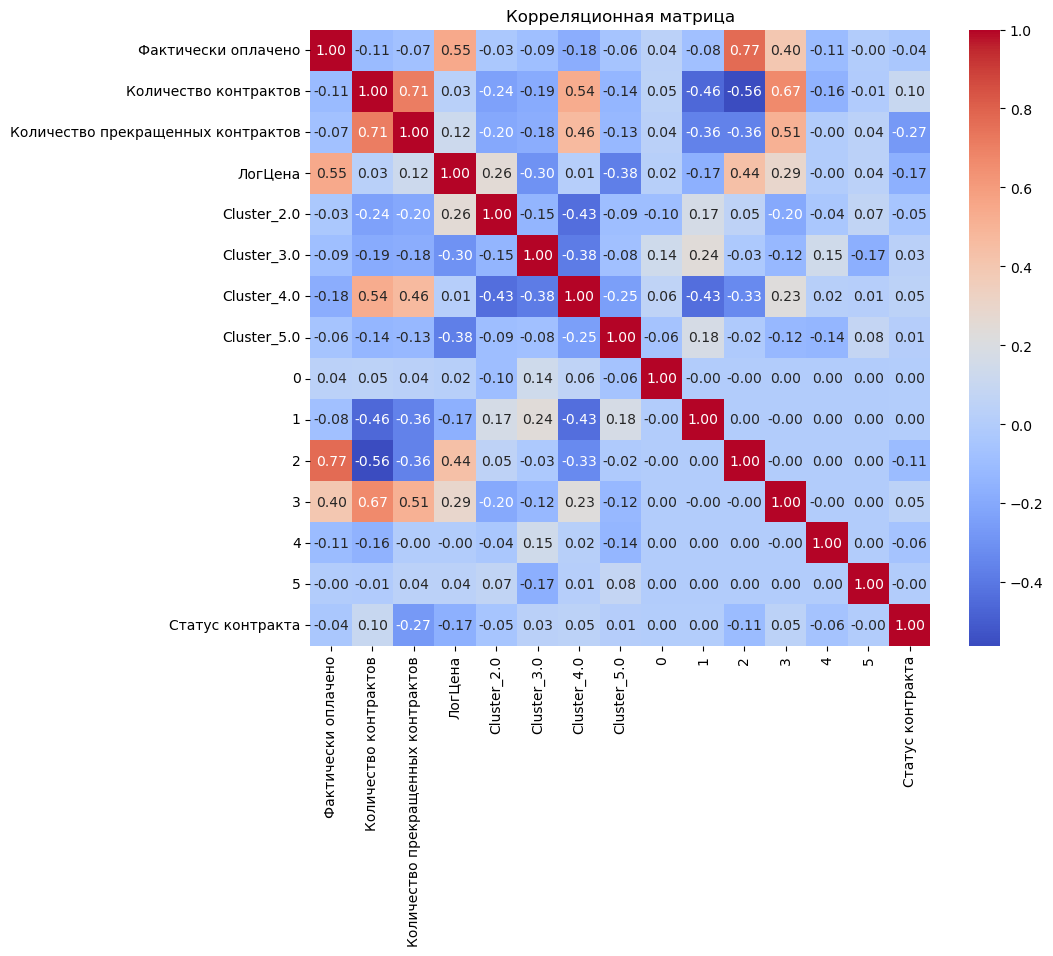

In [132]:
numeric_df_2 =  pd.concat([X_with_pca, y], axis = 1)

corr_matrix_2 = numeric_df_2.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix_2, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Корреляционная матрица")
plt.show()

In [133]:
#Random forest

In [134]:
model = RandomForestClassifier(
    n_estimators=300,     
    max_depth=15,        
    min_samples_split=2,   
    min_samples_leaf=3,   
    class_weight="balanced", 
    random_state=42           
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_tr = model.predict(X_train)

y_prob = model.predict_proba(X_test)[:, 1]
y_pred_custom = (y_prob >= 0.6).astype(int) 

print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))
print("\nClassification report for train:\n", classification_report(y_train, y_pred_tr))
print("\nClassification report with thrashhold:\n", classification_report(y_test, y_pred_custom))

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nБудущая важность:\n", feature_importance)

Confusion matrix:
 [[ 28   7]
 [  9 256]]

Classification report:
               precision    recall  f1-score   support

           0       0.76      0.80      0.78        35
           1       0.97      0.97      0.97       265

    accuracy                           0.95       300
   macro avg       0.87      0.88      0.87       300
weighted avg       0.95      0.95      0.95       300


Classification report for train:
               precision    recall  f1-score   support

           0       0.76      0.95      0.84        80
           1       0.99      0.96      0.98       619

    accuracy                           0.96       699
   macro avg       0.88      0.96      0.91       699
weighted avg       0.97      0.96      0.96       699


Classification report with thrashhold:
               precision    recall  f1-score   support

           0       0.62      0.83      0.71        35
           1       0.98      0.93      0.95       265

    accuracy                           

In [135]:
first_df.head()

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков
0,1001146420,200000.00,200000.00,200000.00,199990.25,199990.25,1,3732000.0,3277000.0,455000.0,1,0,0
1,1001333318,280192.52,280192.52,280192.52,246645.01,246645.01,1,61659000.0,24491000.0,37168000.0,1,0,0
2,102002711630,786656.66,786656.66,786656.66,786656.66,786656.66,1,NaN,NaN,0.0,0,0,0
3,141701766795,204449.00,102224.50,140000.00,74767.36,37383.68,2,NaN,NaN,0.0,2,0,1
4,2100009963,554000.00,277000.00,438000.00,554000.00,277000.00,2,1756000.0,729000.0,1027000.0,0,0,0


In [136]:
pd.set_option("display.float_format", "{:.2f}".format)
first_df[['Сумма контрактов','Средняя цена контракта', 'Количество контрактов']].describe().round(2)

,Сумма контрактов,Средняя цена контракта,Количество контрактов
count,388.00,388.00,388.00
mean,7283234.95,4348836.53,2.57
std,20935845.13,14231905.62,7.06
min,4611.63,4611.63,1.00
25%,132133.42,112839.39,1.00
50%,551036.64,359919.72,1.00
75%,3737617.78,1862629.48,2.00
max,169174555.77,158852995.49,113.00


In [137]:
group_status = not_changed_df.groupby("Статус контракта", as_index = False).agg({'ИНН исполнителя': 'nunique'})
group_status

,Статус контракта,ИНН исполнителя
0,Исполнение завершено,355
1,Исполнение прекращено,75


In [141]:
not_changed_df["Статус контракта"]

0       Исполнение завершено
1       Исполнение завершено
2       Исполнение завершено
3       Исполнение завершено
4       Исполнение завершено
               ...          
995     Исполнение завершено
996     Исполнение завершено
997     Исполнение завершено
998     Исполнение завершено
999    Исполнение прекращено
Name: Статус контракта, Length: 1000, dtype: object